Dataset shape: (6433, 21)
Columns: ['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls', 'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough', 'pickup_hour', 'pickup_weekday', 'pickup_date', 'duration_min', 'day_period', 'passenger_group', 'distance_group']


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough,pickup_hour,pickup_weekday,pickup_date,duration_min,day_period,passenger_group,distance_group
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.00,2.15,0.00,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan,20,Saturday,2019-03-23,6.25,Evening,1 passenger,Short (<=2 mi)
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.00,0.00,0.00,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan,16,Monday,2019-03-04,7.08,Day,1 passenger,Short (<=2 mi)
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.50,2.36,0.00,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan,17,Wednesday,2019-03-27,7.40,Day,1 passenger,Short (<=2 mi)
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.00,6.15,0.00,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan,1,Sunday,2019-03-10,25.87,Night,1 passenger,Long (>5 mi)
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.00,1.10,0.00,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan,13,Saturday,2019-03-30,9.53,Day,3+ passengers,Medium (2-5 mi)


,missing_values
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


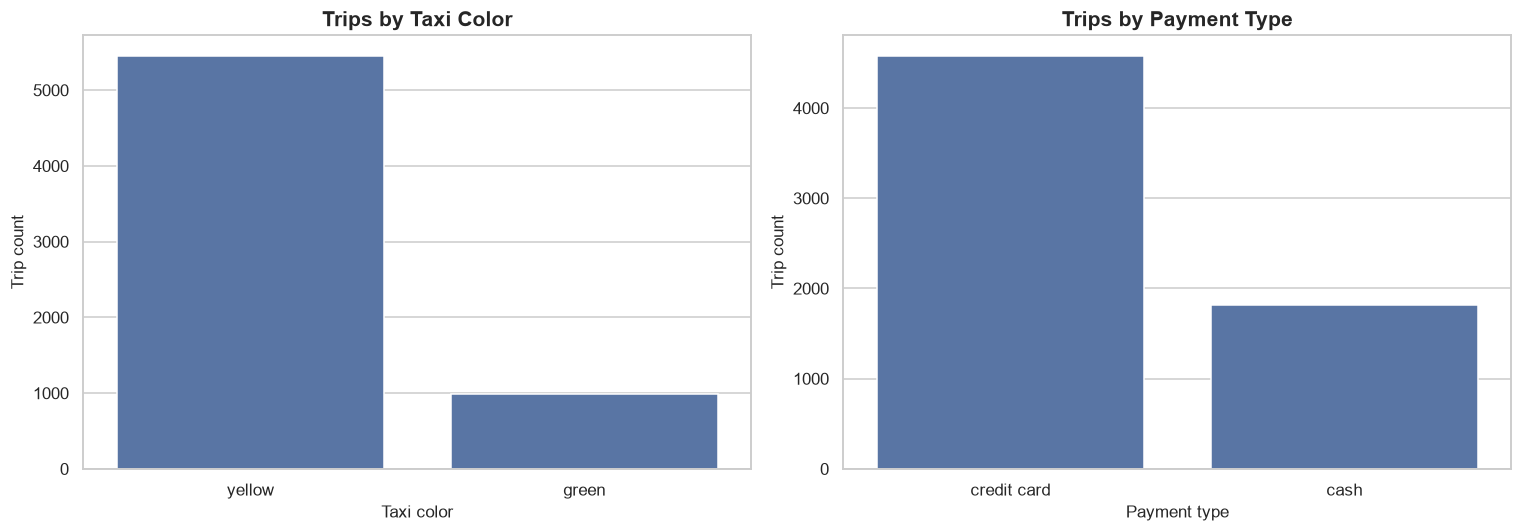

In [9]:
# If needed, install packages in a separate cell:
# %pip install seaborn pandas numpy matplotlib scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11
})

OUTPUT_DIR = Path("taxi_analysis_output")
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = sns.load_dataset("taxis")
data = df.copy()

for col in ["pickup", "dropoff"]:
    data[col] = pd.to_datetime(data[col], errors="coerce")

for col in ["passengers", "distance", "fare", "tip", "tolls", "total"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data["pickup_hour"] = data["pickup"].dt.hour
data["pickup_weekday"] = data["pickup"].dt.day_name()
data["pickup_date"] = data["pickup"].dt.date
data["duration_min"] = (data["dropoff"] - data["pickup"]).dt.total_seconds() / 60
data["day_period"] = np.select(
    [data["pickup_hour"].between(6, 17), data["pickup_hour"].between(18, 23)],
    ["Day", "Evening"], default="Night"
)
data["passenger_group"] = pd.cut(
    data["passengers"], bins=[-0.1, 1, 2, np.inf],
    labels=["1 passenger", "2 passengers", "3+ passengers"]
)
data["distance_group"] = pd.cut(
    data["distance"], bins=[-0.001, 2, 5, np.inf],
    labels=["Short (<=2 mi)", "Medium (2-5 mi)", "Long (>5 mi)"]
)

print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())
display(data.head())
display(data.isna().sum().rename("missing_values").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=data, x="color", order=data["color"].value_counts().index, ax=axes[0])
axes[0].set_title("Trips by Taxi Color")
axes[0].set_xlabel("Taxi color")
axes[0].set_ylabel("Trip count")

sns.countplot(data=data, x="payment", order=data["payment"].value_counts().index, ax=axes[1])
axes[1].set_title("Trips by Payment Type")
axes[1].set_xlabel("Payment type")
axes[1].set_ylabel("Trip count")
plt.tight_layout()
plt.show()

,trip_count
passenger_group,
1 passenger,4774
2 passengers,876
3+ passengers,783


Average passengers per trip: 1.54
Maximum passenger count: 6


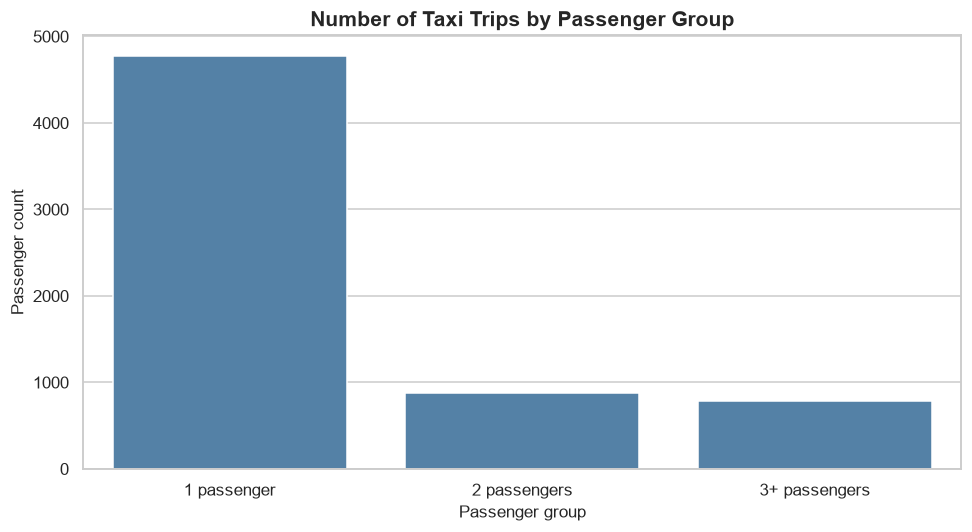

,fare,tip,distance,total
passenger_group,,,,
1 passenger,13.03,1.93,3.02,18.34
2 passengers,13.17,2.10,2.98,18.91
3+ passengers,13.37,2.13,3.12,19.16


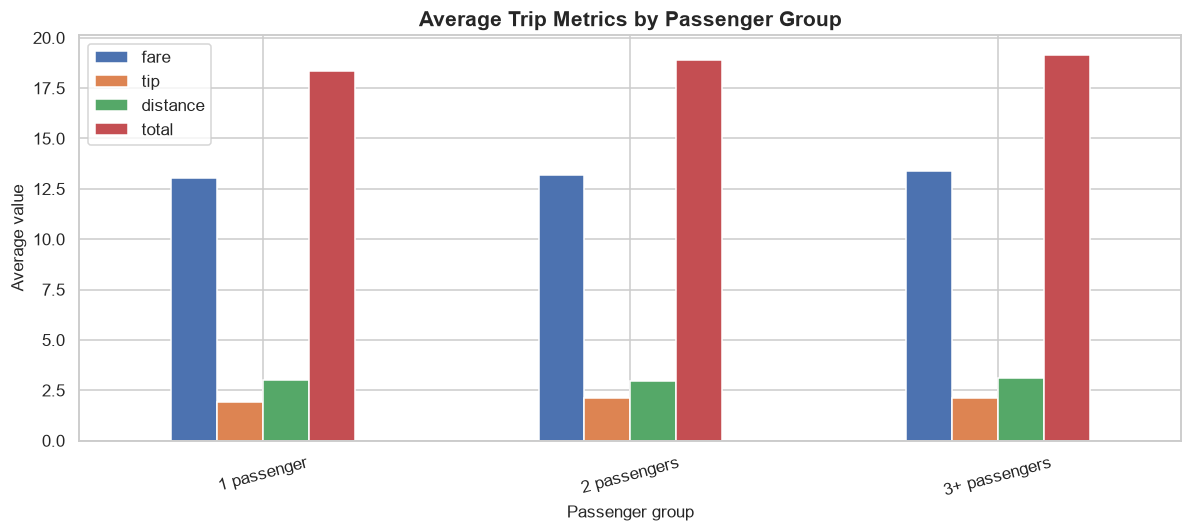

In [10]:
passenger_data = data.dropna(subset=["passenger_group"]).copy()

passenger_counts = passenger_data["passenger_group"].value_counts().reindex(
    ["1 passenger", "2 passengers", "3+ passengers"]
)
display(passenger_counts.rename("trip_count").to_frame())
print("Average passengers per trip:", round(passenger_data["passengers"].mean(), 2))
print("Maximum passenger count:", passenger_data["passengers"].max())

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=passenger_counts.index, y=passenger_counts.values, color="steelblue", ax=ax)
ax.set_title("Number of Taxi Trips by Passenger Group")
ax.set_xlabel("Passenger group")
ax.set_ylabel("Passenger count")
plt.tight_layout()
plt.show()

passenger_means = passenger_data.groupby("passenger_group", observed=False)[
    ["fare", "tip", "distance", "total"]
].mean()
display(passenger_means.round(2))

passenger_means.plot(kind="bar", figsize=(11, 5))
plt.title("Average Trip Metrics by Passenger Group")
plt.xlabel("Passenger group")
plt.ylabel("Average value")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()